Real-World Dataset Analysis: Global Superstore

Name: Arifa Begum R

1. Dataset and Objective
Source:Global Superstore dataset (Kaggle), orders from a global retailer with sales, quantity, discount, profit and shipping cost.

Objective:find which categories, markets and discount levels affect sales and profit.

In [5]:
%mamba install pandas matplotlib

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 2.130 seconds
All requested packages already installed.


In [18]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

path = Path("data/Global_Superstore2.csv")
if not path.exists():
    path = Path("Global_Superstore2.csv")

df = pd.read_csv(path, encoding="latin-1")
print(df.shape)

(51290, 24)


In [19]:
from pathlib import Path

path = Path("data/Global_Superstore2.csv")
if not path.exists():
    path = Path("Global_Superstore2.csv")

df = pd.read_csv(path, encoding="latin-1")
print(df.shape)
df.head()

(51290, 24)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,32298,CA-2012-124891,31-07-2012,31-07-2012,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,2309.650,7,0.0,762.1845,933.57,Critical
1,26341,IN-2013-77878,05-02-2013,07-02-2013,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",3709.395,9,0.1,-288.7650,923.63,Critical
2,25330,IN-2013-71249,17-10-2013,18-10-2013,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID",5175.171,9,0.1,919.9710,915.49,Medium
3,13524,ES-2013-1579342,28-01-2013,30-01-2013,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless",2892.510,5,0.1,-96.5400,910.16,Medium
4,47221,SG-2013-4320,05-11-2013,06-11-2013,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed",2832.960,8,0.0,311.5200,903.04,Critical


2. Data Exploration

In [20]:
print("Shape:", df.shape)
print()
df.info()

Shape: (51290, 24)

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          51290 non-null  int64  
 1   Order ID        51290 non-null  str    
 2   Order Date      51290 non-null  str    
 3   Ship Date       51290 non-null  str    
 4   Ship Mode       51290 non-null  str    
 5   Customer ID     51290 non-null  str    
 6   Customer Name   51290 non-null  str    
 7   Segment         51290 non-null  str    
 8   City            51290 non-null  str    
 9   State           51290 non-null  str    
 10  Country         51290 non-null  str    
 11  Postal Code     9994 non-null   float64
 12  Market          51290 non-null  str    
 13  Region          51290 non-null  str    
 14  Product ID      51290 non-null  str    
 15  Category        51290 non-null  str    
 16  Sub-Category    51290 non-null  str    
 17  Product Name    51290 

In [21]:
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print()
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
Postal Code    41296
dtype: int64

Duplicate rows: 0


In [22]:
df[["Sales", "Quantity", "Discount", "Profit", "Shipping Cost"]].describe().round(2)

,Sales,Quantity,Discount,Profit,Shipping Cost
count,51290.00,51290.00,51290.00,51290.00,51290.00
mean,246.49,3.48,0.14,28.61,26.38
std,487.57,2.28,0.21,174.34,57.30
min,0.44,1.00,0.00,-6599.98,0.00
25%,30.76,2.00,0.00,0.00,2.61
50%,85.05,3.00,0.00,9.24,7.79
75%,251.05,5.00,0.20,36.81,24.45
max,22638.48,14.00,0.85,8399.98,933.57


Insight:
- The dataset has 51,290 orders and 24 columns. There are no duplicate rows.
- Only Postal Code has missing values: 41,296 of 51,290 (about 80.5%) are blank. It is too incomplete to use, so I will drop it.
- Order Date and Ship Date are stored as text (str). They must be converted to datetime before any time analysis.
- Sales is heavily right-skewed: the mean is 246.49 but the median is only 85.05, and the maximum is 22,638.48. A few very large orders pull the average up, so the median describes a typical order better.
- Profit ranges from -6,599.98 to 8,399.98. The median is only 9.24 and the 25th percentile is 0, so many orders earn little or lose money.
- Discount has a median of 0 but a maximum of 0.85 (85%). Most orders have no discount, but a few are heavily discounted.
- Shipping Cost is also skewed (mean 26.38, median 7.79, maximum 933.57).

3. Data Cleaning

In [23]:
df_clean = df.copy()

# Drop columns that are not useful
df_clean = df_clean.drop(columns=["Postal Code", "Row ID"])

# Fix data types: text to datetime
df_clean["Order Date"] = pd.to_datetime(df_clean["Order Date"], format="%d-%m-%Y")
df_clean["Ship Date"] = pd.to_datetime(df_clean["Ship Date"], format="%d-%m-%Y")

# New columns
df_clean["Order Year"] = df_clean["Order Date"].dt.year
df_clean["Order Month"] = df_clean["Order Date"].dt.month
df_clean["Delivery Days"] = (df_clean["Ship Date"] - df_clean["Order Date"]).dt.days

print(df_clean.shape)

(51290, 25)


In [24]:
print(df[df["Postal Code"].notnull()]["Country"].unique())

<StringArray>
['United States']
Length: 1, dtype: str


In [25]:
df_clean = df.copy()

# Drop columns that are not useful
df_clean = df_clean.drop(columns=["Postal Code", "Row ID"])

# Fix data types: text to datetime
df_clean["Order Date"] = pd.to_datetime(df_clean["Order Date"], format="%d-%m-%Y")
df_clean["Ship Date"] = pd.to_datetime(df_clean["Ship Date"], format="%d-%m-%Y")

# New columns
df_clean["Order Year"] = df_clean["Order Date"].dt.year
df_clean["Order Month"] = df_clean["Order Date"].dt.month
df_clean["Delivery Days"] = (df_clean["Ship Date"] - df_clean["Order Date"]).dt.days

print(df_clean[["Order Date", "Ship Date"]].dtypes)
print(df_clean["Order Date"].min(), "to", df_clean["Order Date"].max())

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object
2011-01-01 00:00:00 to 2014-12-31 00:00:00


In [26]:
for col in ["Sales", "Profit"]:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df_clean[col] < low) | (df_clean[col] > high)).sum()
    print(col, "outliers:", n, f"({n / len(df_clean) * 100:.1f}%)")

print("Loss-making orders:", (df_clean["Profit"] < 0).sum())

Sales outliers: 5655 (11.0%)
Profit outliers: 9755 (19.0%)
Loss-making orders: 12544


Insight (cleaning):
- Postal Code is filled only for United States orders (9,994 rows), so the other 41,296 rows are blank by design, not by error. I dropped the column, along with Row ID, which is just an index.
- Order Date and Ship Date were converted from text to datetime. The data covers 1 Jan 2011 to 31 Dec 2014, four full years, so yearly and monthly trends can be analyzed.
- I added Order Year, Order Month and Delivery Days columns for the later analysis.
- Using the IQR rule, 11.0% of Sales values and 19.0% of Profit values are outliers. I kept them, because in retail these are real large orders and real big losses, not data errors. Removing them would hide the most important business cases.
- 12,544 orders (about 24.5%) lost money. Roughly one in four orders has negative profit, which is worth investigating.

4. Exploratory Data Analysis

In [27]:
for col in ["Category", "Market", "Segment"]:
    summary = df_clean.groupby(col)[["Sales", "Profit"]].sum().round(0)
    summary["Profit Margin %"] = (summary["Profit"] / summary["Sales"] * 100).round(1)
    print(summary.sort_values("Profit", ascending=False))
    print()

                     Sales    Profit  Profit Margin %
Category                                             
Technology       4744557.0  663779.0             14.0
Office Supplies  3787070.0  518474.0             13.7
Furniture        4110874.0  285205.0              6.9

            Sales    Profit  Profit Margin %
Market                                      
APAC    3585744.0  436000.0             12.2
EU      2938089.0  372830.0             12.7
US      2297201.0  286397.0             12.5
LATAM   2164605.0  221643.0             10.2
Africa   783773.0   88872.0             11.3
EMEA     806161.0   43898.0              5.4
Canada    66928.0   17817.0             26.6

                 Sales    Profit  Profit Margin %
Segment                                          
Consumer     6507949.0  749240.0             11.5
Corporate    3824698.0  441208.0             11.5
Home Office  2309855.0  277009.0             12.0



In [28]:
yearly = df_clean.groupby("Order Year")[["Sales", "Profit"]].sum().round(0)
yearly["Sales Growth %"] = (yearly["Sales"].pct_change() * 100).round(1)
print(yearly)

                Sales    Profit  Sales Growth %
Order Year                                     
2011        2259451.0  248941.0             NaN
2012        2677439.0  307415.0            18.5
2013        3405746.0  406935.0            27.2
2014        4299866.0  504166.0            26.3


In [29]:
df_clean["Discount Band"] = pd.cut(
    df_clean["Discount"],
    bins=[-0.01, 0, 0.2, 0.4, 1],
    labels=["No discount", "Low (0-20%)", "Medium (20-40%)", "High (>40%)"]
)
disc = df_clean.groupby("Discount Band", observed=True).agg(
    Orders=("Sales", "count"),
    Avg_Profit=("Profit", "mean"),
    Total_Profit=("Profit", "sum"),
).round(2)
print(disc)

                 Orders  Avg_Profit  Total_Profit
Discount Band                                    
No discount       29009       61.04    1770695.27
Low (0-20%)       10953       46.69     511444.10
Medium (20-40%)    4367      -42.88    -187271.06
High (>40%)        6961      -90.13    -627411.02


Insight (EDA):
- Category:Technology earns the most profit (663,779, margin 14.0%). Furniture has higher sales than Office Supplies (4.11M vs 3.79M) but earns far less profit (285,205 vs 518,474). Its margin is only 6.9%, about half of the other two categories, so Furniture sells a lot but keeps little.
- Market:APAC has the highest sales (3.59M) and profit (436,000). EMEA is the weakest: 806,161 in sales but only 43,898 profit, a margin of 5.4% against 10% to 13% elsewhere. Canada has the highest margin (26.6%), but its sales are tiny (66,928), so it is too small to compare fairly.
- Segment:Consumer is the biggest segment with about 51% of total sales. All three segments have a similar margin (11.5% to 12.0%), so the customer segment does not change profitability much.
- Yearly trend:Sales almost doubled from 2.26M in 2011 to 4.30M in 2014 (about 90% growth), with growth of 18.5%, 27.2% and 26.3% per year. Profit doubled too (248,941 to 504,166), and the margin rose slightly from about 11.0% to 11.7%, so growth did not come at the cost

5. Data Visualization

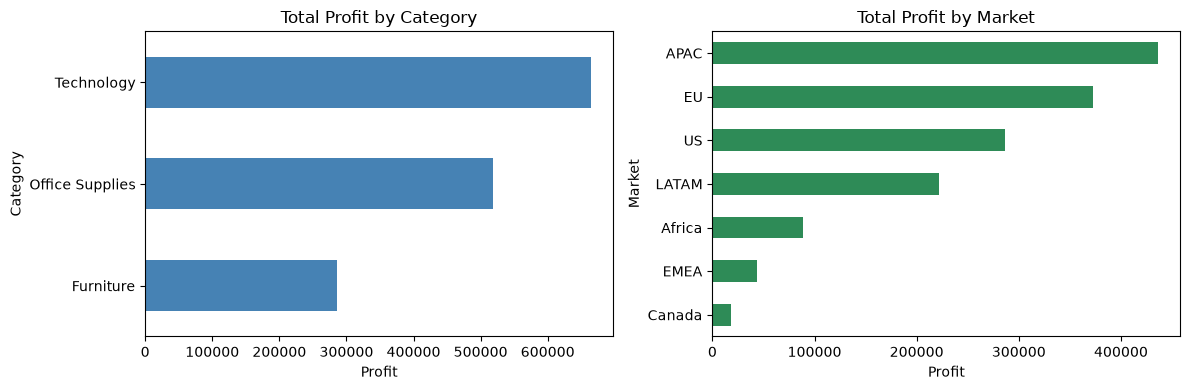

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_clean.groupby("Category")["Profit"].sum().sort_values().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Total Profit by Category")
axes[0].set_xlabel("Profit")

df_clean.groupby("Market")["Profit"].sum().sort_values().plot(kind="barh", ax=axes[1], color="seagreen")
axes[1].set_title("Total Profit by Market")
axes[1].set_xlabel("Profit")

plt.tight_layout()
plt.show()

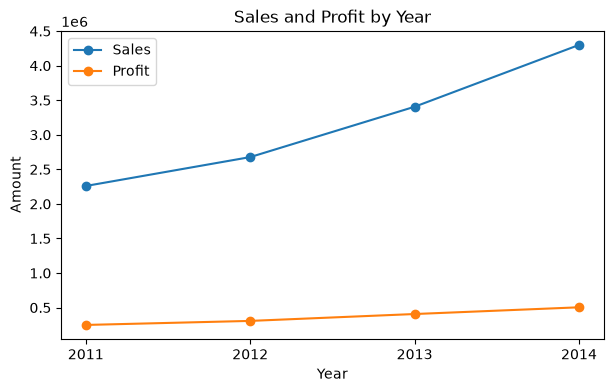

In [31]:
yearly[["Sales", "Profit"]].plot(kind="line", marker="o", figsize=(7, 4))
plt.title("Sales and Profit by Year")
plt.xlabel("Year")
plt.ylabel("Amount")
plt.xticks([2011, 2012, 2013, 2014])
plt.show()

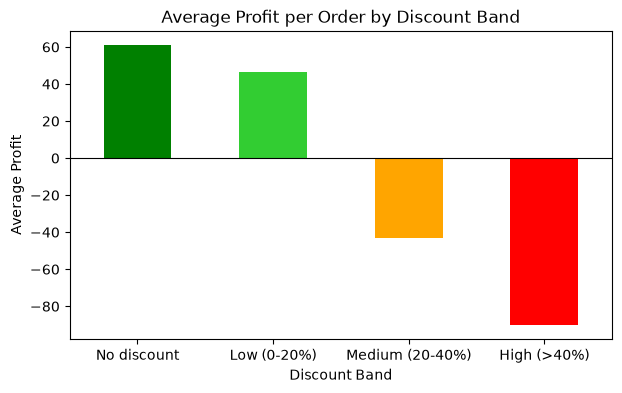

In [32]:
disc["Avg_Profit"].plot(kind="bar", color=["green", "limegreen", "orange", "red"], figsize=(7, 4))
plt.title("Average Profit per Order by Discount Band")
plt.xlabel("Discount Band")
plt.ylabel("Average Profit")
plt.xticks(rotation=0)
plt.axhline(0, color="black", linewidth=0.8)
plt.show()

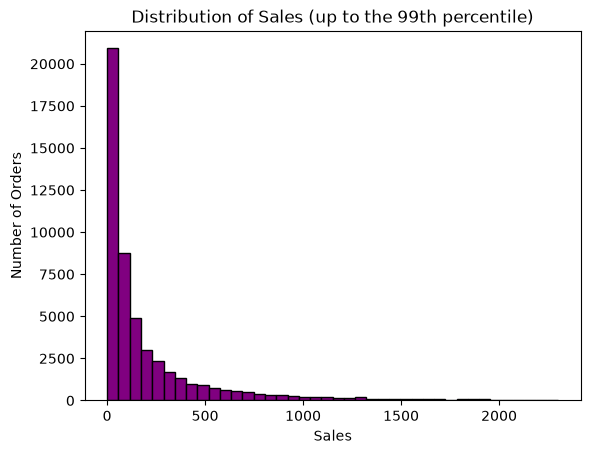

Sales percentiles:
0.50      85.05
0.90     632.23
0.99    2301.00
Name: Sales, dtype: float64


In [33]:
cap = df_clean["Sales"].quantile(0.99)
plt.hist(df_clean[df_clean["Sales"] <= cap]["Sales"], bins=40, color="purple", edgecolor="black")
plt.title("Distribution of Sales (up to the 99th percentile)")
plt.xlabel("Sales")
plt.ylabel("Number of Orders")
plt.show()

print("Sales percentiles:")
print(df_clean["Sales"].quantile([0.5, 0.9, 0.99]).round(2))

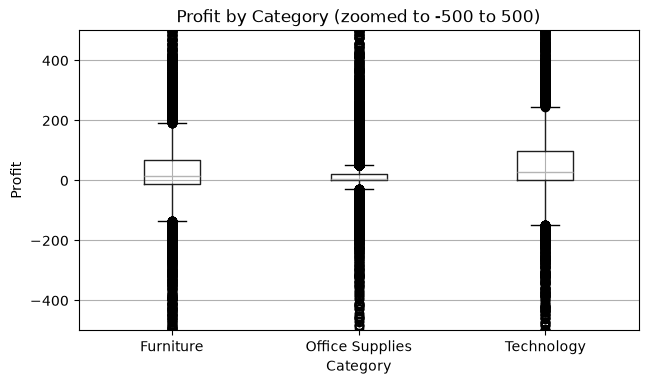

Median profit by category:
Category
Furniture          15.50
Office Supplies     6.55
Technology         29.94
Name: Profit, dtype: float64


In [34]:
df_clean.boxplot(column="Profit", by="Category", figsize=(7, 4))
plt.ylim(-500, 500)
plt.title("Profit by Category (zoomed to -500 to 500)")
plt.suptitle("")
plt.ylabel("Profit")
plt.show()

print("Median profit by category:")
print(df_clean.groupby("Category")["Profit"].median().round(2))

Insight (charts):
- Profit by category and market:Technology has the longest profit bar and Furniture the shortest, even though Furniture sales are higher than Office Supplies. Among markets, APAC leads and EMEA has by far the smallest profit relative to its sales.
- Yearly trend:both sales and profit rise every year from 2011 to 2014, and the two lines move almost together. This means growth came from selling more, not from earning more per sale.
- Discount vs profit:average profit per order is positive for no discount and low discounts, and drops below zero from the 20% discount band onwards, with the high band (above 40%) the worst.
- Distribution of sales:the histogram is strongly right-skewed. The first bar alone holds about 21,000 orders, roughly 41% of all orders. The median order is 85.05, 90% of orders are below 632.23, and 99% are below 2,301. Only a small share of orders are large, yet they raise the mean to 246.49, so the median is the better measure of a typical order.
- Profit by category (box plot):median profit per order is highest for Technology (29.94), then Furniture (15.50), then Office Supplies (6.55). Office Supplies has the narrowest box, so its profits are small and steady, while Technology has the widest box, so its profits vary the most. All three categories have many points beyond the whiskers on both the profit and loss side,

6. Correlation Analysis

               Sales  Quantity  Discount  Profit  Shipping Cost  Delivery Days
Sales          1.000     0.314    -0.087   0.485          0.768         -0.005
Quantity       0.314     1.000    -0.020   0.104          0.273          0.004
Discount      -0.087    -0.020     1.000  -0.316         -0.079         -0.002
Profit         0.485     0.104    -0.316   1.000          0.354          0.002
Shipping Cost  0.768     0.273    -0.079   0.354          1.000         -0.143
Delivery Days -0.005     0.004    -0.002   0.002         -0.143          1.000


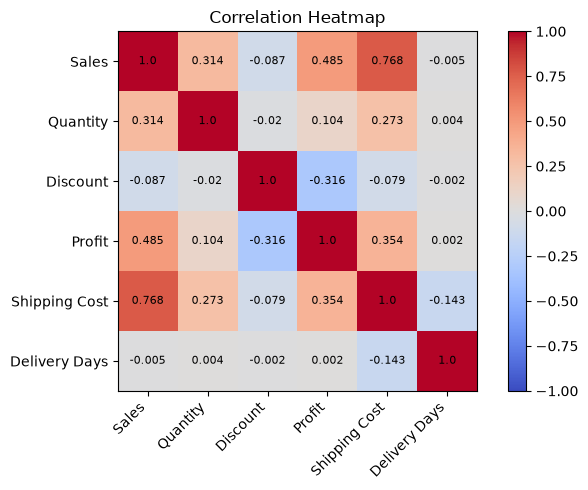

In [35]:
num_cols = ["Sales", "Quantity", "Discount", "Profit", "Shipping Cost", "Delivery Days"]
corr = df_clean[num_cols].corr().round(3)
print(corr)

plt.figure(figsize=(7, 5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(num_cols)), num_cols, rotation=45, ha="right")
plt.yticks(range(len(num_cols)), num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        plt.text(j, i, corr.iloc[i, j], ha="center", va="center", fontsize=8)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [36]:
pairs = corr.unstack().reset_index()
pairs.columns = ["Variable 1", "Variable 2", "Correlation"]
pairs = pairs[pairs["Variable 1"] < pairs["Variable 2"]]
pairs["Abs"] = pairs["Correlation"].abs()
print(pairs.sort_values("Abs", ascending=False).drop(columns="Abs").to_string(index=False))

   Variable 1    Variable 2  Correlation
        Sales Shipping Cost        0.768
       Profit         Sales        0.485
       Profit Shipping Cost        0.354
     Discount        Profit       -0.316
     Quantity         Sales        0.314
     Quantity Shipping Cost        0.273
Delivery Days Shipping Cost       -0.143
       Profit      Quantity        0.104
     Discount         Sales       -0.087
     Discount Shipping Cost       -0.079
     Discount      Quantity       -0.020
Delivery Days         Sales       -0.005
Delivery Days      Quantity        0.004
Delivery Days      Discount       -0.002
Delivery Days        Profit        0.002


In [37]:
spearman = df_clean[["Sales", "Discount", "Profit", "Quantity"]].corr(method="spearman").round(3)
print("Spearman (rank-based):")
print(spearman)

Spearman (rank-based):
          Sales  Discount  Profit  Quantity
Sales     1.000    -0.100   0.490     0.416
Discount -0.100     1.000  -0.596     0.018
Profit    0.490    -0.596   1.000     0.201
Quantity  0.416     0.018   0.201     1.000


Insight (correlation):
- Strongest pair: Sales and Shipping Cost (0.768).Bigger orders cost more to ship. This is likely because shipping is charged on order size or weight. Because the two move together, they should not both be used as separate predictors in a model.
- Profit and Sales (0.485):a moderate positive link. Higher sales tend to bring higher profit, but not reliably. Sales explains only about 24% of the variation in profit (0.485 squared), so a big sale does not guarantee a profit.
- Profit and Shipping Cost (0.354):a weak positive link. Shipping does not create profit. Large orders have both higher shipping cost and higher profit, so this link comes through order size.
- Discount and Profit (-0.316 Pearson, -0.596 Spearman):the only meaningful negative link with profit. The rank-based Spearman value is much stronger than Pearson, so the relationship is consistent but not a straight line, and large outliers weaken the Pearson value. This is the strongest relationship Profit has in the Spearman matrix, stronger than Profit and Sales (0.490), which matches the earlier finding that heavy discounts lose money.
- Discount has almost no link with Sales (-0.087) or Quantity (-0.020):discounts do not go with bigger orders or more units. In this data, discounting cuts profit without raising order size.
- Quantity and Sales (0.314, Spearman 0.416):a moderate link. Buying more units raises sales, but the price per unit varies a lot between products, so quantity alone does not explain sales.
- Delivery Days is close to zero with Sales, Profit, Quantity and Discount (between -0.005 and 0.004): delivery time has no linear relationship with order value or profit. Its only noticeable link is a weak negative one with Shipping Cost (-0.143), which may mean faster shipping modes cost more.
- Limits:correlation does not prove causation. Pearson only measures straight-line relationships, so a value near zero does not rule out other kinds of links. The data also covers only 2011 to 2014.

## 7. Key Findings and Recommendations

**Key findings**
- Sales and profit about doubled from 2011 to 2014 (sales 2.26M to 4.30M).
- Technology earns the most profit, while Furniture has a low margin (6.9%) despite high sales.
- EMEA has the weakest margin (5.4%), while APAC leads in sales and profit.
- About 24.5% of orders (12,544) lost money.
- Orders with a discount above 20% lost about 814,682 in total, while orders with no discount or a low discount stayed profitable.
- Discount has a negative link with profit (-0.316, Spearman -0.596) and almost no link with sales or quantity.

**Recommendations**
1. **Limit discounts above 20%.** They lower profit without increasing order size. Review which products and markets receive them.
2. **Review Furniture pricing and costs.** High sales but only a 6.9% margin suggest prices are too low or costs too high.
3. **Investigate EMEA.** Sales are healthy but the margin is 5.4%, so check shipping costs, discounts and product mix there.
4. **Keep investing in Technology and APAC,** the strongest sources of profit.
5. **Study the loss-making orders** by product, market and discount level to find the biggest sources of loss.

**Limitations:** the data covers 2011 to 2014 only, no product-level or cost data was analyzed, and correlations show links, not causes.

## 8. Conclusion
In this task I analyzed the Global Superstore dataset (51,290 orders, 24 columns). I explored its structure, cleaned it (dropped Postal Code, fixed date types, kept real outliers), performed exploratory analysis, made visualizations, and studied the correlation matrix using both Pearson and Spearman methods.

The main finding is that heavy discounting is the clearest driver of lost profit in this dataset, while sales growth over the four years was strong and healthy. The recommendations above turn these findings into practical actions.